# E-Commerce Sales Data Visualization

## Project Overview
This project focuses on creating meaningful visualizations from historical e-commerce sales data to identify sales trends, product performance, country-wise revenue, and customer purchasing patterns.

## Objective
- Transform raw transaction data into meaningful visualizations.
- Identify important sales trends and patterns.
- Compare revenue across countries and products.
- Communicate business insights through charts and graphs

## Project Workflow
1. Load and inspect the dataset.
2. Prepare data for visualization.
3. Create sales performance charts.
4. Analyze country-wise and product-wise performance.
5. Visualize monthly and daily sales trends.
6. Present key business insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_excel("Online Retail.xlsx")

In [3]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
# Create Revenue column
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Convert InvoiceDate into datetime format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Extract month and year
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["Month_Name"] = df["InvoiceDate"].dt.strftime("%B")

# Extract weekday
df["Day_Name"] = df["InvoiceDate"].dt.strftime("%A")

# Display updated dataset
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Month_Name,Day_Name
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010,12,December,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010,12,December,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010,12,December,Wednesday


### Monthly Revenue Trend

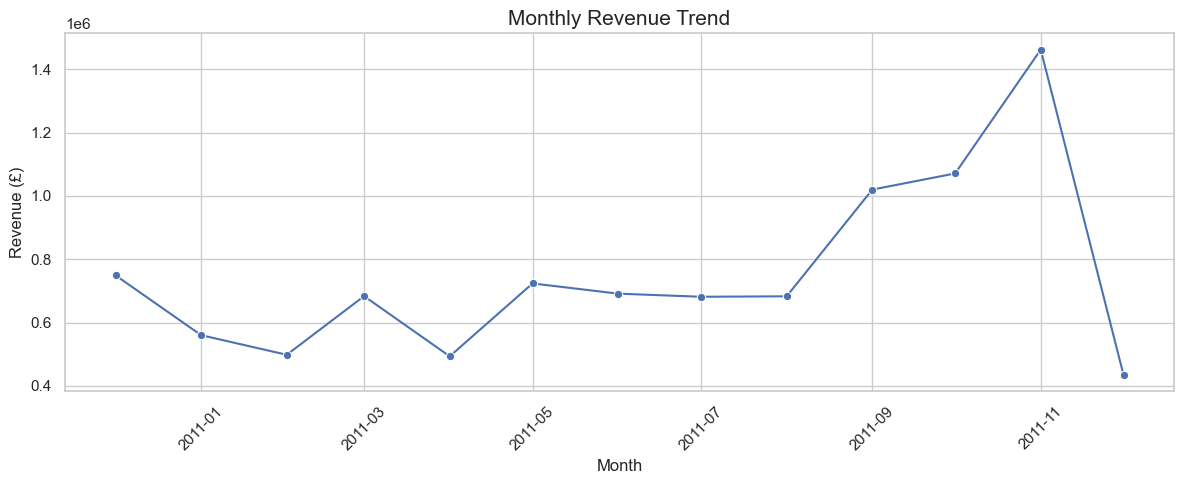

In [8]:
monthly_revenue = (
    df.groupby(
        df["InvoiceDate"].dt.to_period("M")
    )["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue.columns = ["Month", "Revenue"]

# Convert Period to datetime
monthly_revenue["Month"] = monthly_revenue["Month"].dt.to_timestamp()

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Revenue",
    marker="o"
)

plt.title("Monthly Revenue Trend", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Top 10 Countries by Revenue

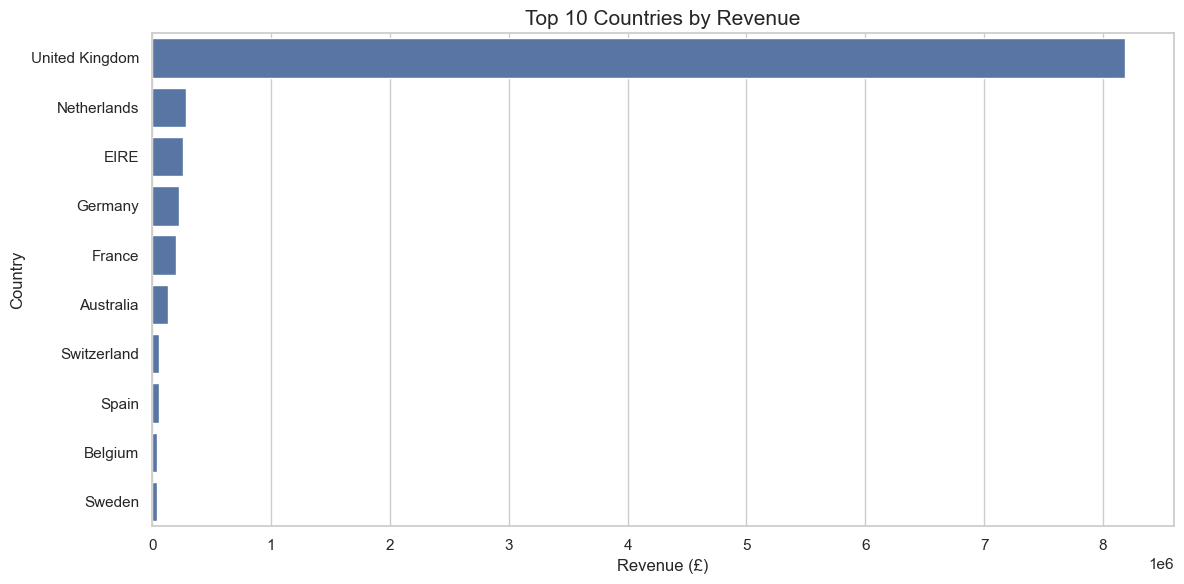

In [9]:
country_revenue = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_revenue,
    x="Revenue",
    y="Country"
)

plt.title("Top 10 Countries by Revenue", fontsize=15)
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.show()

### Top 10 Products by Revenue

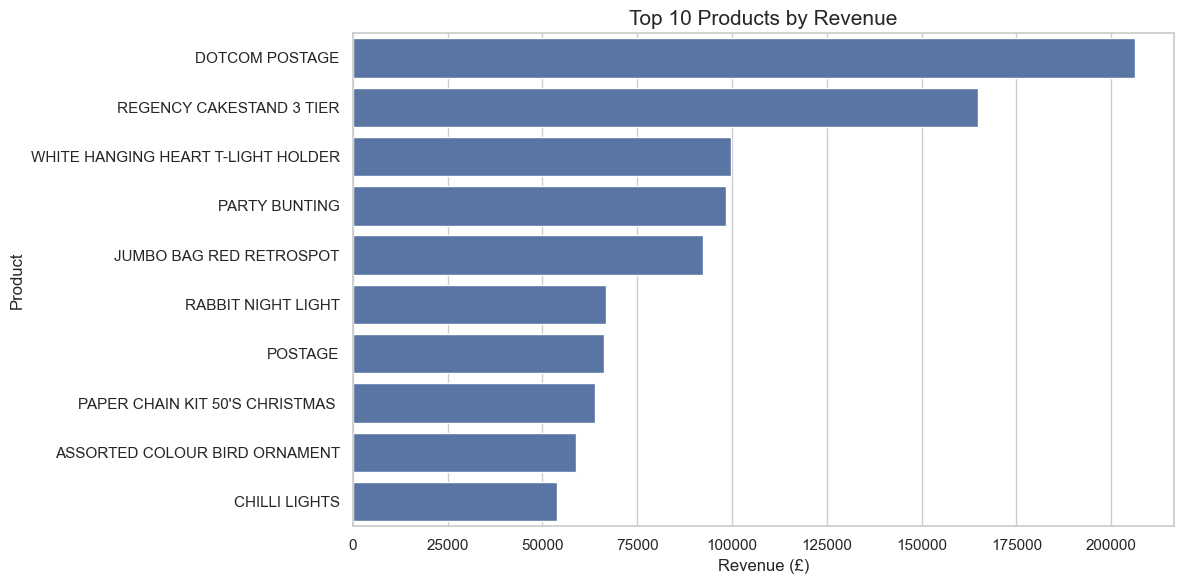

In [11]:
product_revenue = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=product_revenue,
    x="Revenue",
    y="Description"
)

plt.title("Top 10 Products by Revenue", fontsize=15)
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()

plt.show()

### Top 10 Products by Quantity Sold

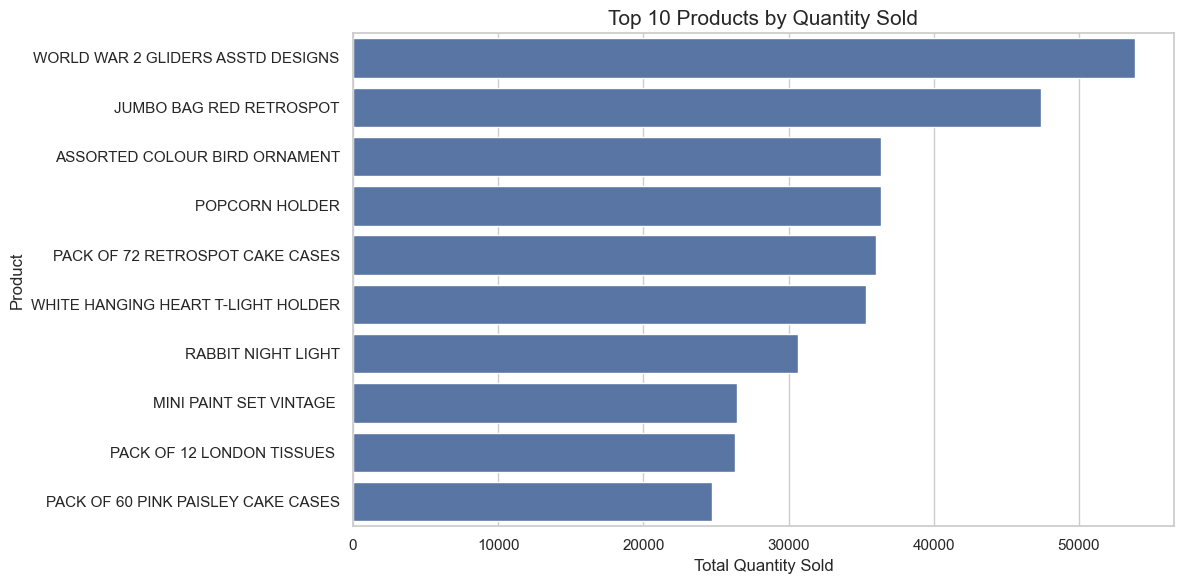

In [12]:
top_products_quantity = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products_quantity,
    x="Quantity",
    y="Description"
)

plt.title("Top 10 Products by Quantity Sold", fontsize=15)
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()

plt.show()

### Weekday vs Weekend Revenue

In [13]:
df["Day_Type"] = np.where(
    df["InvoiceDate"].dt.dayofweek < 5,
    "Weekday",
    "Weekend"
)

day_revenue = (
    df.groupby("Day_Type")["Revenue"]
    .sum()
    .reset_index()
)

day_revenue

,Day_Type,Revenue
0,Weekday,8942069.043
1,Weekend,805678.891


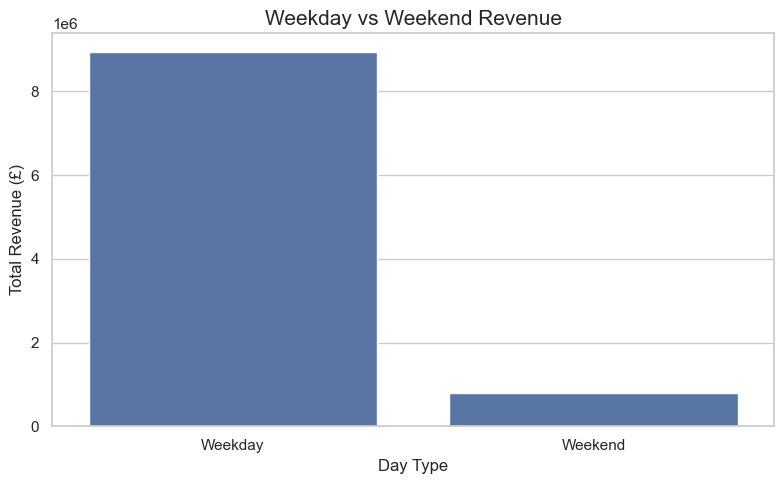

In [14]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=day_revenue,
    x="Day_Type",
    y="Revenue"
)

plt.title("Weekday vs Weekend Revenue", fontsize=15)
plt.xlabel("Day Type")
plt.ylabel("Total Revenue (£)")
plt.tight_layout()

plt.show()

### Monthly Revenue by Year (Seasonality Analysis)

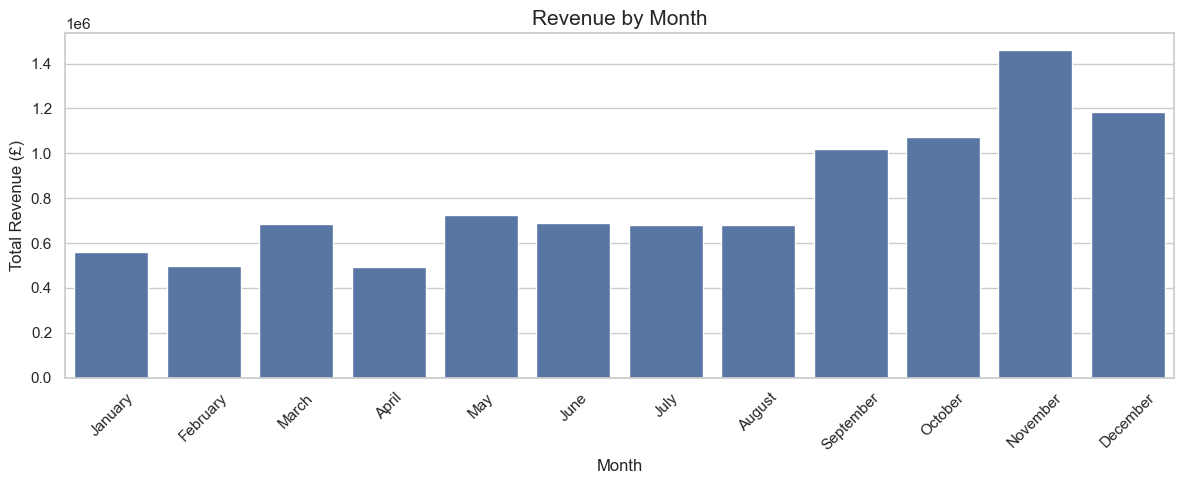

In [15]:
monthly_sales = (
    df.groupby("Month_Name")["Revenue"]
    .sum()
    .reindex([
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ])
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_sales,
    x="Month_Name",
    y="Revenue"
)

plt.title("Revenue by Month", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Total Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Revenue Distribution Analysis

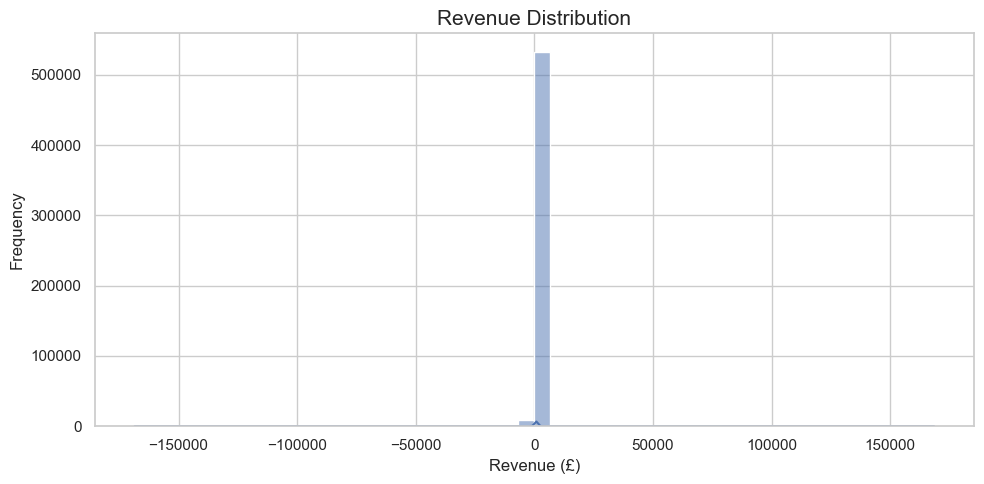

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Revenue",
    bins=50,
    kde=True
)

plt.title("Revenue Distribution", fontsize=15)
plt.xlabel("Revenue (£)")
plt.ylabel("Frequency")
plt.tight_layout()

plt.show()

### Correlation Heatmap

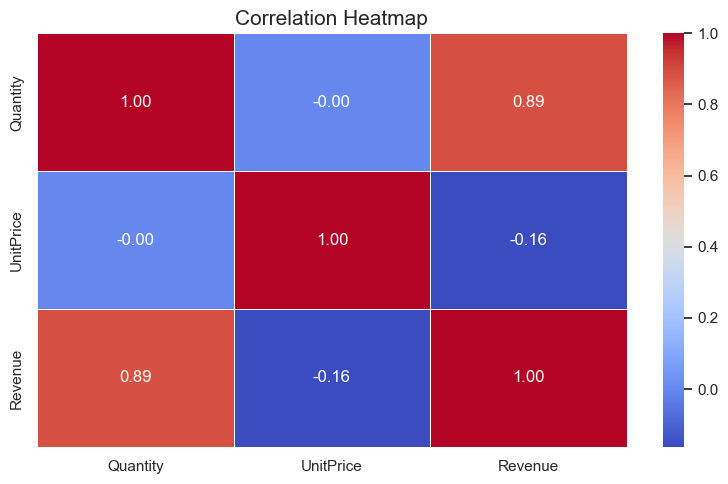

In [18]:
correlation = df[
    ["Quantity", "UnitPrice", "Revenue"]
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap", fontsize=15)
plt.tight_layout()

plt.show()

### Daily Revenue Trend

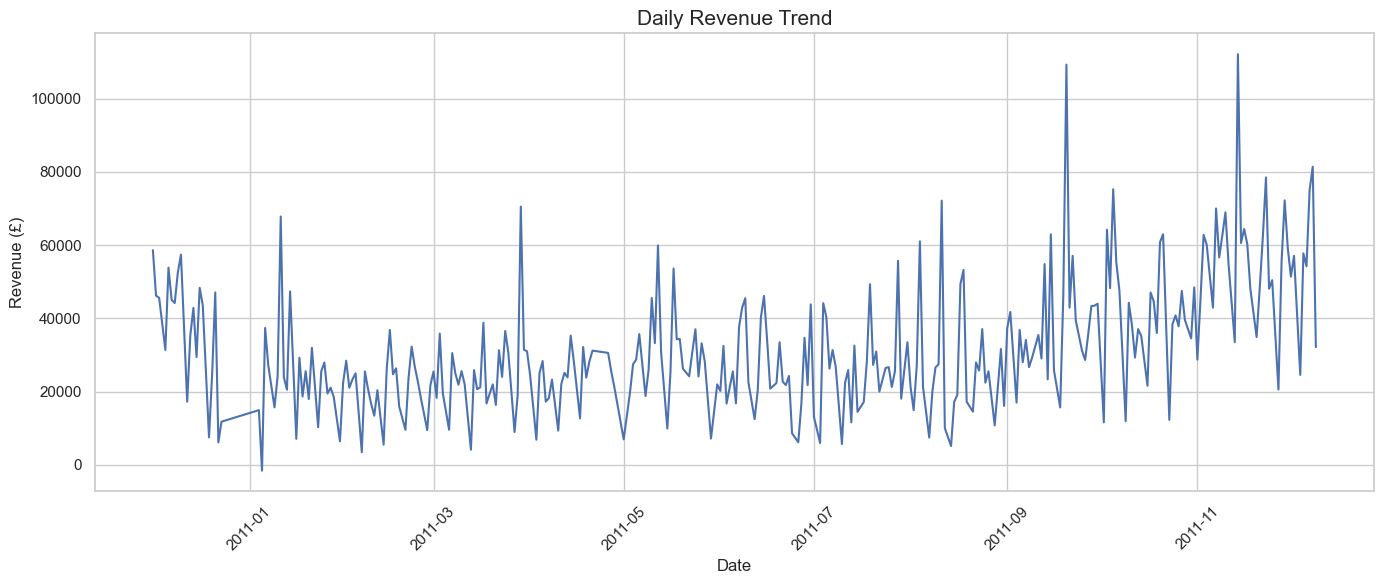

In [19]:
daily_revenue = (
    df.groupby(df["InvoiceDate"].dt.date)["Revenue"]
    .sum()
    .reset_index()
)

daily_revenue.columns = ["Date", "Revenue"]

daily_revenue["Date"] = pd.to_datetime(daily_revenue["Date"])

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_revenue,
    x="Date",
    y="Revenue"
)

plt.title("Daily Revenue Trend", fontsize=15)
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### Country-wise Revenue Contribution

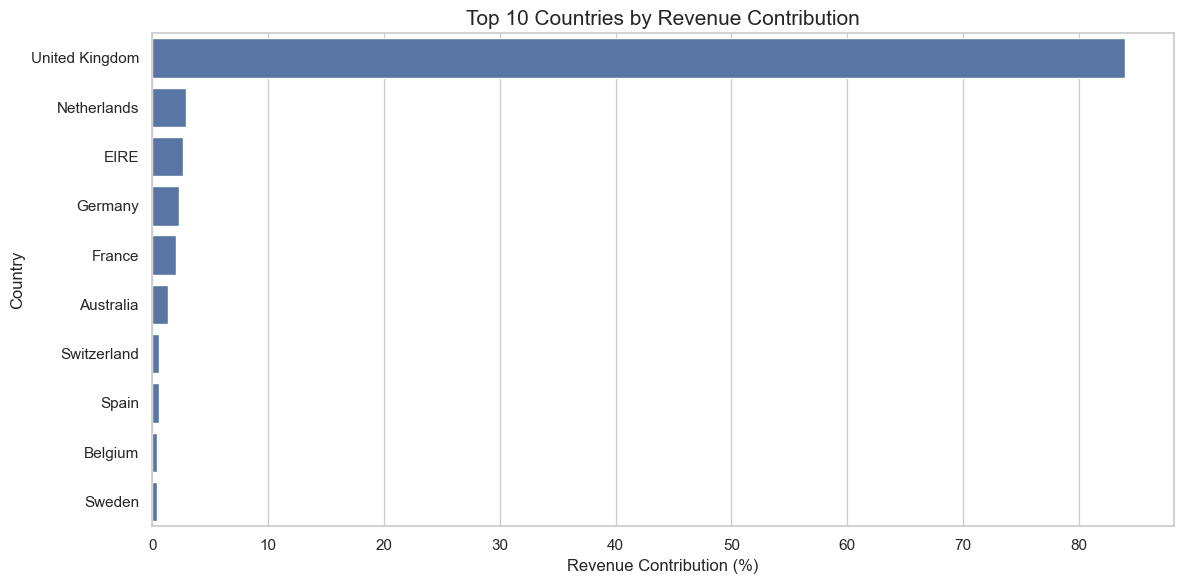

In [20]:
country_contribution = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

country_contribution["Revenue_Percentage"] = (
    country_contribution["Revenue"] /
    df["Revenue"].sum()
) * 100

plt.figure(figsize=(12, 6))

sns.barplot(
    data=country_contribution,
    x="Revenue_Percentage",
    y="Country"
)

plt.title("Top 10 Countries by Revenue Contribution", fontsize=15)
plt.xlabel("Revenue Contribution (%)")
plt.ylabel("Country")
plt.tight_layout()

plt.show()

### Monthly Revenue Comparison Across Years

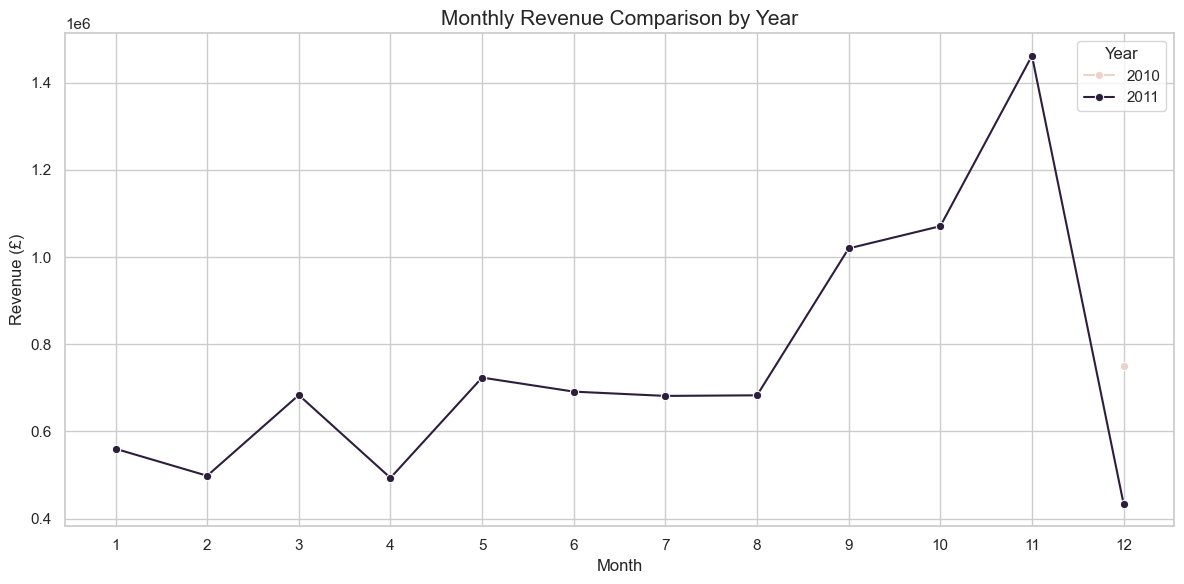

In [21]:
yearly_monthly_revenue = (
    df.groupby(["Year", "Month"])["Revenue"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_monthly_revenue,
    x="Month",
    y="Revenue",
    hue="Year",
    marker="o"
)

plt.title("Monthly Revenue Comparison by Year", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()

plt.show()

### Visualization: Revenue and Quantity Dashboard

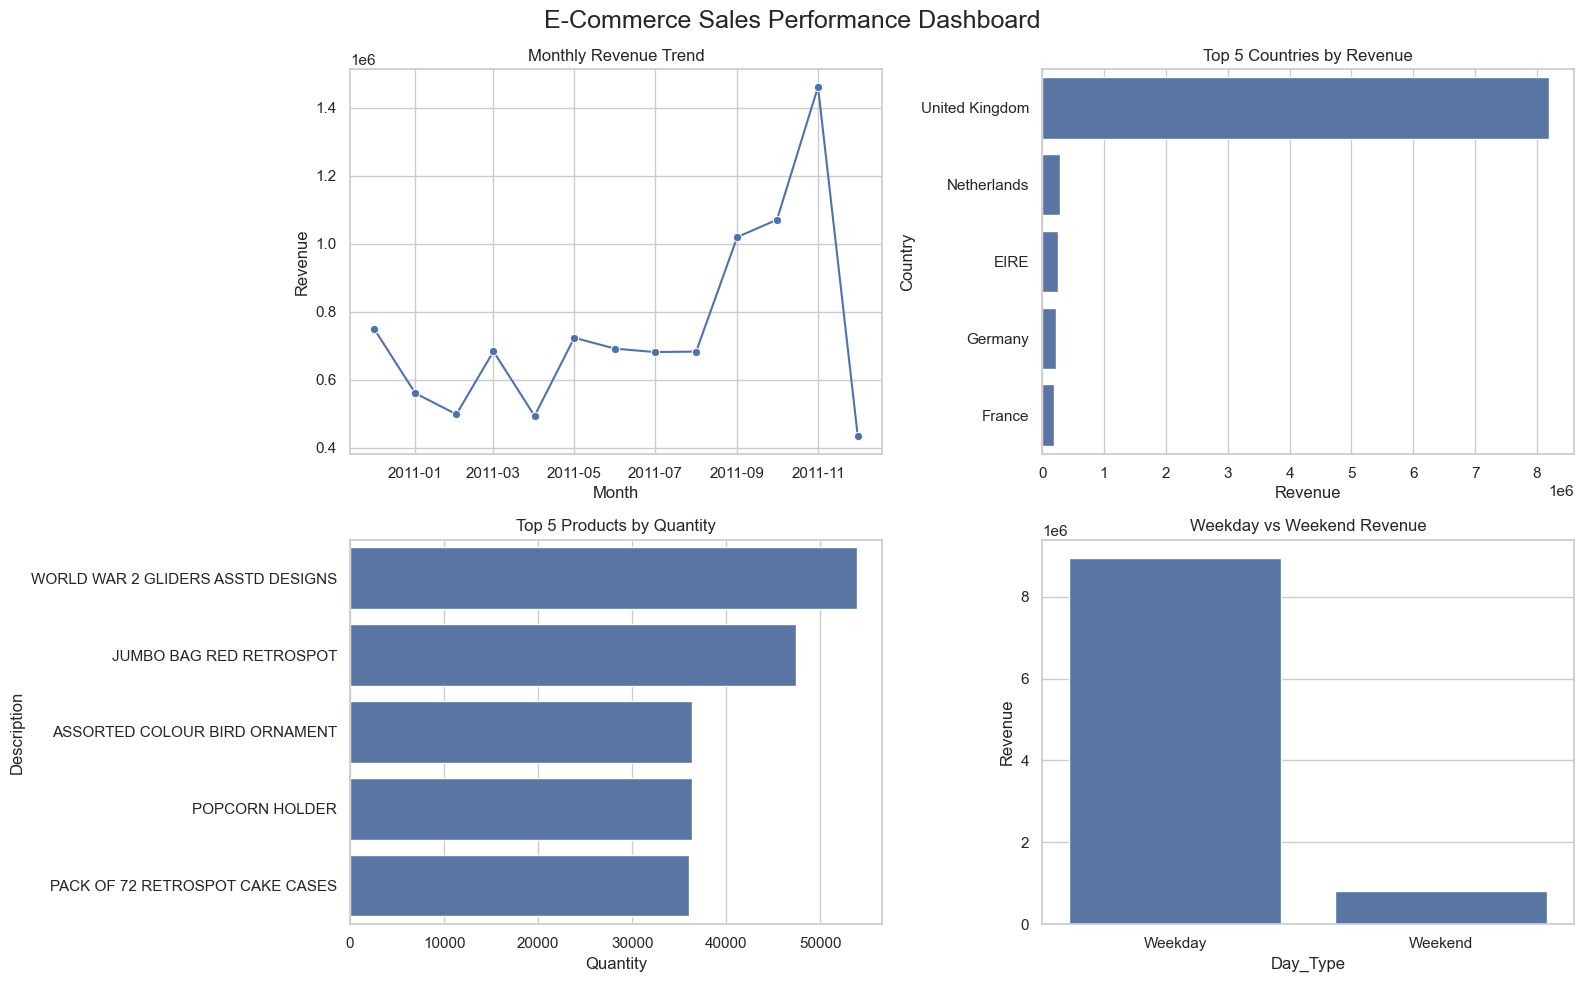

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Monthly Revenue
sns.lineplot(
    data=monthly_revenue,
    x="Month",
    y="Revenue",
    marker="o",
    ax=axes[0, 0]
)
axes[0, 0].set_title("Monthly Revenue Trend")

# 2. Top 5 Countries
sns.barplot(
    data=country_revenue.head(5),
    x="Revenue",
    y="Country",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Top 5 Countries by Revenue")

# 3. Top 5 Products by Quantity
sns.barplot(
    data=top_products_quantity.head(5),
    x="Quantity",
    y="Description",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Top 5 Products by Quantity")

# 4. Weekday vs Weekend Revenue
sns.barplot(
    data=day_revenue,
    x="Day_Type",
    y="Revenue",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Weekday vs Weekend Revenue")

plt.suptitle(
    "E-Commerce Sales Performance Dashboard",
    fontsize=18
)

plt.tight_layout()
plt.show()

# Business Insights and Conclusion

## Key Business Insights

1. **Revenue Performance:** The business generated approximately £9.73 million in recorded net revenue across the dataset.

2. **Country Performance:** The United Kingdom is the largest revenue-generating market, contributing the majority of total revenue.

3. **Monthly Sales Trends:** November 2011 recorded the highest monthly revenue, while December 2011 recorded the lowest.

4. **Product Performance:** Products such as World War 2 Gliders and Jumbo Bag Red Retrospot performed strongly in terms of quantity sold.

5. **Weekday vs Weekend:** Weekdays generated higher total recorded revenue than weekends.

6. **Revenue Distribution:** Revenue values are unevenly distributed, with a large number of smaller transaction lines and some unusually high values.

## Business Recommendations

- Focus on retaining customers in the United Kingdom while exploring opportunities in other countries.
- Prepare inventory and marketing campaigns ahead of high-revenue periods.
- Monitor high-demand products to reduce stock shortages.
- Investigate low-revenue periods and identify opportunities to improve sales.
- Monitor cancelled orders and returns to understand their impact on business performance.

## Conclusion

This project explored an e-commerce retail dataset using Python, Pandas, NumPy, Matplotlib, and Seaborn. Data analysis and visualization helped identify revenue trends, country performance, product demand, and sales patterns.

The findings can help businesses make more informed decisions about inventory planning, market expansion, and sales strategies.